Saving Titanic.csv to Titanic.csv

Dataset loaded successfully!

========== FIRST 5 RECORDS ==========
   PassengerId  Survived  Pclass  \
0          892         0       3   
1          893         1       3   
2          894         0       2   
3          895         0       3   
4          896         1       3   

                                           Name     Sex   Age  SibSp  Parch  \
0                              Kelly, Mr. James    male  34.5      0      0   
1              Wilkes, Mrs. James (Ellen Needs)  female  47.0      1      0   
2                     Myles, Mr. Thomas Francis    male  62.0      0      0   
3                              Wirz, Mr. Albert    male  27.0      0      0   
4  Hirvonen, Mrs. Alexander (Helga E Lindqvist)  female  22.0      1      1   

    Ticket     Fare Cabin Embarked  
0   330911   7.8292   NaN        Q  
1   363272   7.0000   NaN        S  
2   240276   9.6875   NaN        Q  
3   315154   8.6625   NaN        S  
4  3101298  12.2875 

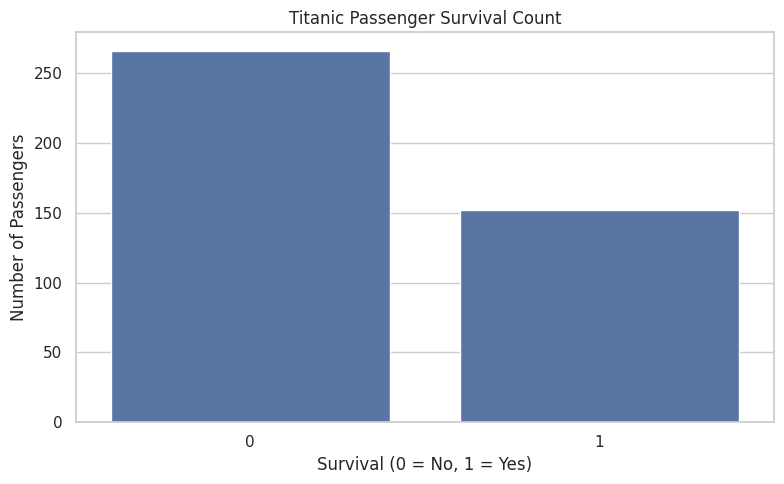

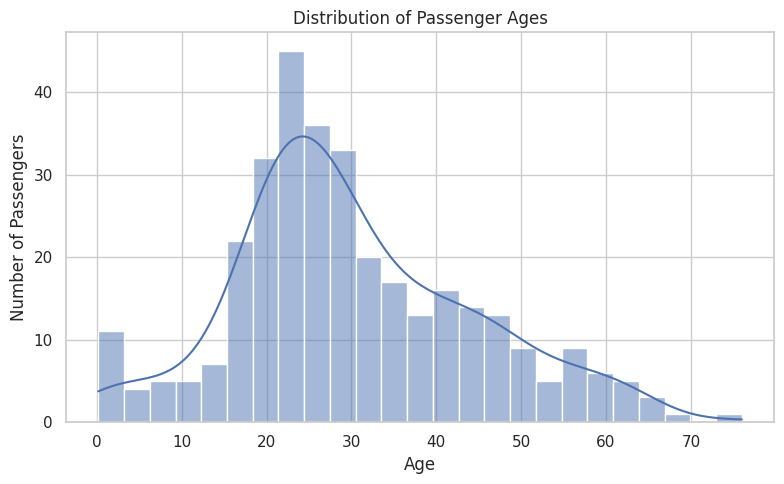

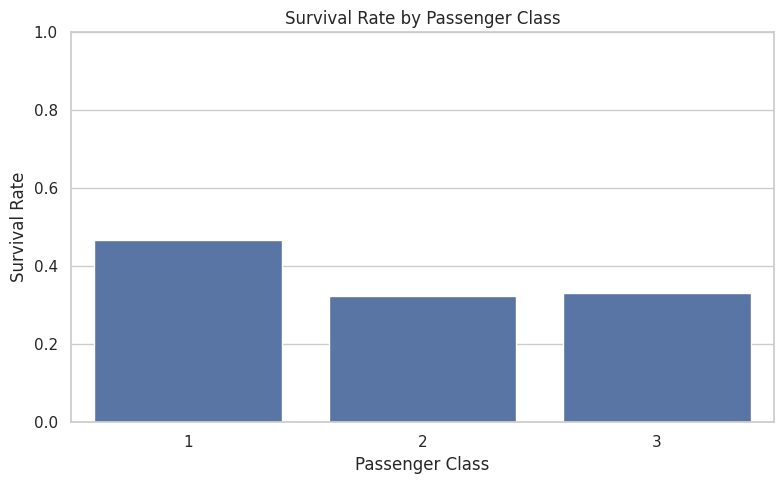

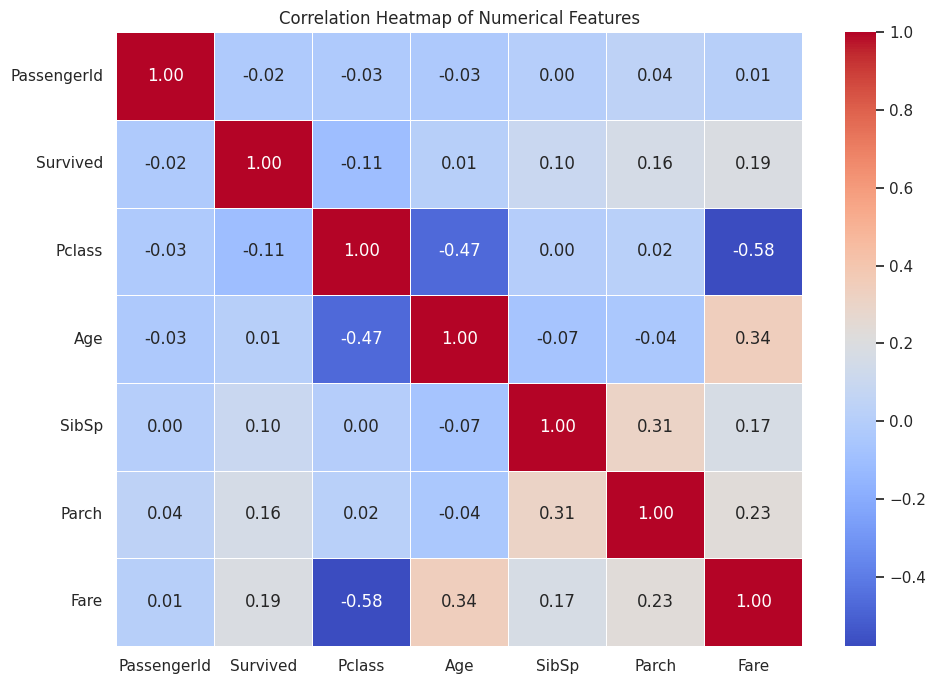


Sex encoding:
{'female': np.int64(0), 'male': np.int64(1)}

Embarked encoding:
{'C': np.int64(0), 'Q': np.int64(1), 'S': np.int64(2)}

Cleaned dataset saved successfully!

Feature scaling completed.

Scaled dataset saved successfully!

========== CLEANED DATASET ==========
   PassengerId  Survived  Pclass  \
0          892         0       3   
1          893         1       3   
2          894         0       2   
3          895         0       3   
4          896         1       3   

                                           Name  Sex   Age  SibSp  Parch  \
0                              Kelly, Mr. James    1  34.5      0      0   
1              Wilkes, Mrs. James (Ellen Needs)    0  47.0      1      0   
2                     Myles, Mr. Thomas Francis    1  62.0      0      0   
3                              Wirz, Mr. Albert    1  27.0      0      0   
4  Hirvonen, Mrs. Alexander (Helga E Lindqvist)    0  22.0      1      1   

    Ticket     Fare  Embarked  
0   330911   7.8292

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


scaled dataset...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


DATA PROFILING COMPLETED
DATA CLEANING COMPLETED
ALL FOUR VISUALIZATIONS COMPLETED
FEATURE SCALING COMPLETED
OUTPUT FILES GENERATED SUCCESSFULLY


In [2]:

from google.colab import files
uploaded = files.upload()
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("\nDataset loaded successfully!")
original_df = df.copy()

print("\n========== FIRST 5 RECORDS ==========")
print(df.head())
print("\n========== DATASET SHAPE ==========")
print(df.shape)
print("\n========== DATA TYPES ==========")
print(df.dtypes)
print("\n========== DATASET INFO ==========")
df.info()
print("\n========== STATISTICAL SUMMARY ==========")
print(df.describe(include="all"))
print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())
print("\n========== DUPLICATE RECORDS ==========")
print(df.duplicated().sum())
df.drop_duplicates(inplace=True)
print("\nDuplicate rows removed.")
if "Age" in df.columns:
    df["Age"] = df["Age"].fillna(df["Age"].median())
if "Fare" in df.columns:
    df["Fare"] = df["Fare"].fillna(df["Fare"].median())

if "Embarked" in df.columns:
    if df["Embarked"].notna().any():
        df["Embarked"] = df["Embarked"].fillna(
            df["Embarked"].mode()[0]
        )
if "Cabin" in df.columns:
    df.drop(columns=["Cabin"], inplace=True)

print("\n========== MISSING VALUES AFTER CLEANING ==========")
print(df.isnull().sum())

print("\n========== CLEANED DATASET SHAPE ==========")
print(df.shape)
sns.set_theme(style="whitegrid")
if "Survived" in original_df.columns:

    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=original_df,
        x="Survived"
    )

    plt.title("Titanic Passenger Survival Count")
    plt.xlabel("Survival (0 = No, 1 = Yes)")
    plt.ylabel("Number of Passengers")
    plt.tight_layout()
    plt.show()
if "Age" in original_df.columns:

    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=original_df,
        x="Age",
        bins=25,
        kde=True
    )

    plt.title("Distribution of Passenger Ages")
    plt.xlabel("Age")
    plt.ylabel("Number of Passengers")
    plt.tight_layout()
    plt.show()
if {"Pclass", "Survived"}.issubset(original_df.columns):

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=original_df,
        x="Pclass",
        y="Survived",
        errorbar=None
    )

    plt.title("Survival Rate by Passenger Class")
    plt.xlabel("Passenger Class")
    plt.ylabel("Survival Rate")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()


numeric_df = df.select_dtypes(include=np.number)

if numeric_df.shape[1] >= 2:

    plt.figure(figsize=(10, 7))

    sns.heatmap(
        numeric_df.corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=0.5
    )

    plt.title("Correlation Heatmap of Numerical Features")
    plt.tight_layout()
    plt.show()


encoders = {}

for col in ["Sex", "Embarked"]:

    if col in df.columns:

        encoder = LabelEncoder()

        df[col] = encoder.fit_transform(df[col].astype(str))

        encoders[col] = dict(
            zip(
                encoder.classes_,
                encoder.transform(encoder.classes_)
            )
        )

        print(f"\n{col} encoding:")
        print(encoders[col])


cleaned_file = "cleaned_titanic.csv"

df.to_csv(cleaned_file, index=False)

print("\nCleaned dataset saved successfully!")


scaled_df = df.copy()


scale_cols = ["Age", "Fare", "SibSp", "Parch"]

available_cols = [
    col for col in scale_cols
    if col in scaled_df.columns
]

scaler = StandardScaler()

if available_cols:

    scaled_df[available_cols] = scaler.fit_transform(
        scaled_df[available_cols]
    )

print("\nFeature scaling completed.")



scaled_file = "scaled_titanic.csv"

scaled_df.to_csv(scaled_file, index=False)

print("\nScaled dataset saved successfully!")


print("\n========== CLEANED DATASET ==========")
print(df.head())

print("\n========== SCALED DATASET ==========")
print(scaled_df.head())

print("\n========== FINAL DATASET INFORMATION ==========")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\n========== REMAINING MISSING VALUES ==========")
print(df.isnull().sum())


print("\ncleaned dataset...")
files.download(cleaned_file)

print("\nscaled dataset...")
files.download(scaled_file)

print("\n==============================================")
print("DATA PROFILING COMPLETED")
print("DATA CLEANING COMPLETED")
print("ALL FOUR VISUALIZATIONS COMPLETED")
print("FEATURE SCALING COMPLETED")
print("OUTPUT FILES GENERATED SUCCESSFULLY")
print("==============================================")
